# 02 · pandas Fundamentals: HR Employee Attrition

An introduction to pandas `Series` and `DataFrame` objects using the IBM HR Analytics
Employee Attrition dataset: selecting data, adding/removing columns, label-based lookups,
summary statistics, recoding values, boolean filtering and `groupby` comparisons.

## Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Notebooks run with the notebook folder as the working directory
DATA_DIR = Path("..") / "data"

## Series

In [2]:
# A Series is a 1-D labelled array: values plus an index
temperature = [33, 19, 15, 89, 11, -5, 9]
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

series_from_list = pd.Series(temperature, index=days)
series_from_list

Mon    33
Tue    19
Wed    15
Thu    89
Fri    11
Sat    -5
Sun     9
dtype: int64

In [3]:
# From a dictionary: keys become the index
my_dict = {"Mon": 33, "Tue": 19, "Wed": 15, "Thu": 89, "Fri": 11, "Sat": -5, "Sun": 9}
series_from_dict = pd.Series(my_dict)
series_from_dict

Mon    33
Tue    19
Wed    15
Thu    89
Fri    11
Sat    -5
Sun     9
dtype: int64

In [4]:
# From a NumPy array: pandas creates a default 0..n-1 index
my_array = np.linspace(0, 10, 15)
series_from_ndarray = pd.Series(my_array)
series_from_ndarray

0      0.000000
1      0.714286
2      1.428571
3      2.142857
4      2.857143
5      3.571429
6      4.285714
7      5.000000
8      5.714286
9      6.428571
10     7.142857
11     7.857143
12     8.571429
13     9.285714
14    10.000000
dtype: float64

In [5]:
# Vectorised operations work on Series just like on NumPy arrays
2 * series_from_list

Mon     66
Tue     38
Wed     30
Thu    178
Fri     22
Sat    -10
Sun     18
dtype: int64

In [6]:
series_from_list + 2

Mon    35
Tue    21
Wed    17
Thu    91
Fri    13
Sat    -3
Sun    11
dtype: int64

In [7]:
# NumPy ufuncs also accept a Series and keep its index
np.exp(series_from_list)

Mon    2.146436e+14
Tue    1.784823e+08
Wed    3.269017e+06
Thu    4.489613e+38
Fri    5.987414e+04
Sat    6.737947e-03
Sun    8.103084e+03
dtype: float64

## Loading the HR dataset

In [8]:
data = pd.read_excel(DATA_DIR / "hr_employee_attrition.xlsx", index_col="EmployeeNumber")
data.shape

(1470, 34)

In [9]:
data.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement',
       'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus',
       'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18',
       'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='object')

In [10]:
data.index

Index([   1,    2,    4,    5,    7,    8,   10,   11,   12,   13,
       ...
       2054, 2055, 2056, 2057, 2060, 2061, 2062, 2064, 2065, 2068],
      dtype='int64', name='EmployeeNumber', length=1470)

In [11]:
data.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EnvironmentSatisfaction,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
EmployeeNumber,,,,,,,,,,,,,,,,,,,,,
1,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,...,1,80,0,8,0,1,6,4,0,5
2,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,3,...,4,80,1,10,3,3,10,7,1,7
4,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
5,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,4,...,3,80,0,8,3,3,8,7,3,0
7,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,1,...,4,80,1,6,3,3,2,2,2,2


In [12]:
data.tail()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EnvironmentSatisfaction,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
EmployeeNumber,,,,,,,,,,,,,,,,,,,,,
2061,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,3,...,3,80,1,17,3,3,5,2,0,3
2062,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,4,...,1,80,1,9,5,3,7,7,1,7
2064,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2,...,2,80,1,6,0,3,6,2,0,3
2065,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,4,...,4,80,0,17,3,2,9,6,0,8
2068,34,No,Travel_Rarely,628,Research & Development,8,3,Medical,1,2,...,1,80,0,6,3,4,4,3,1,2


## Selecting, adding and removing columns

In [13]:
# One column returns a Series; .head() shows the first five values
data["Age"].head()

EmployeeNumber
1    41
2    49
4    37
5    33
7    27
Name: Age, dtype: int64

In [14]:
# A list of columns returns a DataFrame
data[["Age", "Gender", "YearsAtCompany"]].head()

,Age,Gender,YearsAtCompany
EmployeeNumber,,,
1,41,Female,6
2,49,Male,10
4,37,Male,0
5,33,Female,8
7,27,Male,2


In [15]:
# Adding a column derived from another
data["AgeInMonths"] = 12 * data["Age"]
data["AgeInMonths"].head()

EmployeeNumber
1    492
2    588
4    444
5    396
7    324
Name: AgeInMonths, dtype: int64

In [16]:
# Remove columns: del works for one column, drop() for one or many.
# EmployeeCount is 1 for every row, so it carries no information.
del data["AgeInMonths"]
data = data.drop(columns="EmployeeCount")
data.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField',
       'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement',
       'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus',
       'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18',
       'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='object')

## Row selection: by position and by label

In [17]:
# .iloc selects by position: rows 10 to 14
data["BusinessTravel"].iloc[10:15]

EmployeeNumber
14    Travel_Rarely
15    Travel_Rarely
16    Travel_Rarely
18    Travel_Rarely
19    Travel_Rarely
Name: BusinessTravel, dtype: object

In [18]:
data.iloc[10:15]

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
EmployeeNumber,,,,,,,,,,,,,,,,,,,,,
14,35,No,Travel_Rarely,809,Research & Development,16,3,Medical,1,Male,...,3,80,1,6,5,3,5,4,0,3
15,29,No,Travel_Rarely,153,Research & Development,15,2,Life Sciences,4,Female,...,4,80,0,10,3,3,9,5,0,8
16,31,No,Travel_Rarely,670,Research & Development,26,1,Life Sciences,1,Male,...,4,80,1,5,1,2,5,2,4,3
18,34,No,Travel_Rarely,1346,Research & Development,19,2,Medical,2,Male,...,3,80,1,3,2,3,2,2,1,2
19,28,Yes,Travel_Rarely,103,Research & Development,24,3,Life Sciences,3,Male,...,2,80,0,6,4,3,4,2,0,3


In [19]:
# .loc selects by index label - here the EmployeeNumber
selected_employee_numbers = [15, 94, 337, 1120]
data.loc[selected_employee_numbers, "YearsAtCompany"]

EmployeeNumber
15      9
94      5
337     2
1120    7
Name: YearsAtCompany, dtype: int64

In [20]:
data.loc[selected_employee_numbers]

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
EmployeeNumber,,,,,,,,,,,,,,,,,,,,,
15,29,No,Travel_Rarely,153,Research & Development,15,2,Life Sciences,4,Female,...,4,80,0,10,3,3,9,5,0,8
94,29,No,Travel_Rarely,1328,Research & Development,2,3,Life Sciences,3,Male,...,4,80,1,6,3,3,5,4,0,4
337,31,No,Travel_Frequently,1327,Research & Development,3,4,Medical,2,Male,...,1,80,1,9,3,3,2,2,2,2
1120,29,No,Travel_Rarely,1107,Research & Development,28,4,Life Sciences,3,Female,...,1,80,1,11,1,3,7,5,1,7


In [21]:
# A single value: .loc[row_label, column_label]
data.loc[94, "YearsAtCompany"]

5

## Summary statistics

In [22]:
data['Department'].value_counts()

Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64

In [23]:
data['Attrition'].value_counts()

Attrition
No     1233
Yes     237
Name: count, dtype: int64

In [24]:
# normalize=True returns proportions instead of counts
data["Attrition"].value_counts(normalize=True)

Attrition
No     0.838776
Yes    0.161224
Name: proportion, dtype: float64

In [25]:
attrition_rate = data["Attrition"].value_counts(normalize=True)["Yes"]
print(f"Attrition rate: {attrition_rate:.1%}")

Attrition rate: 16.1%


In [26]:
data['HourlyRate'].mean()

65.89115646258503

In [27]:
data['YearsAtCompany'].describe()

count    1470.000000
mean        7.008163
std         6.126525
min         0.000000
25%         3.000000
50%         5.000000
75%         9.000000
max        40.000000
Name: YearsAtCompany, dtype: float64

In [28]:
# Five longest-serving employees and their EmployeeNumbers
longest_serving = data["YearsAtCompany"].sort_values(ascending=False).head(5)
print(longest_serving)
longest_serving.index

EmployeeNumber
165     40
131     37
1578    36
374     36
776     34
Name: YearsAtCompany, dtype: int64


Index([165, 131, 1578, 374, 776], dtype='int64', name='EmployeeNumber')

## Recoding numeric levels as labels

In [29]:
# JobSatisfaction and JobInvolvement are coded 1-4; map them to readable labels
level_labels = {1: "Low", 2: "Medium", 3: "High", 4: "Very High"}

data["JobSatisfaction"] = data["JobSatisfaction"].map(level_labels)
data["JobInvolvement"] = data["JobInvolvement"].map(level_labels)
data["JobSatisfaction"].head()

EmployeeNumber
1    Very High
2       Medium
4         High
5         High
7       Medium
Name: JobSatisfaction, dtype: object

In [30]:
data['JobSatisfaction'].value_counts()

JobSatisfaction
Very High    459
High         442
Low          289
Medium       280
Name: count, dtype: int64

In [31]:
100 * data['JobSatisfaction'].value_counts(normalize=True)

JobSatisfaction
Very High    31.224490
High         30.068027
Low          19.659864
Medium       19.047619
Name: proportion, dtype: float64

## Boolean filtering

In [32]:
# A comparison returns a boolean Series (one True/False per row)
(data["JobSatisfaction"] == "Low").head()

EmployeeNumber
1    False
2    False
4    False
5    False
7    False
Name: JobSatisfaction, dtype: bool

In [33]:
# Use the boolean Series inside .loc to keep only matching rows
data.loc[data["JobSatisfaction"] == "Low"].index

Index([  10,   20,   27,   31,   33,   38,   51,   52,   54,   68,
       ...
       1975, 1980, 1998, 2021, 2023, 2038, 2054, 2055, 2057, 2062],
      dtype='int64', name='EmployeeNumber', length=289)

In [34]:
# Combine conditions with & (and) / | (or); each condition needs its own parentheses
data.loc[(data["JobSatisfaction"] == "Low") & (data["JobInvolvement"] == "Low")].index

Index([33, 235, 454, 615, 1019, 1037, 1237, 1460, 1478, 1544, 1611, 1622, 1905,
       1956],
      dtype='int64', name='EmployeeNumber')

In [35]:
# isin() is a cleaner way to write several == conditions joined by |
subset_of_interest = data.loc[data["JobSatisfaction"].isin(["Low", "Very High"])]
subset_of_interest.shape

(748, 33)

In [36]:
subset_of_interest['JobSatisfaction'].value_counts()

JobSatisfaction
Very High    459
Low          289
Name: count, dtype: int64

## Grouping: Low vs Very High job satisfaction

In [37]:
grouped = subset_of_interest.groupby("JobSatisfaction")

# .groups maps each group name to the index labels in that group
grouped.groups.keys()

dict_keys(['Low', 'Very High'])

In [38]:
grouped.get_group('Low').head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
EmployeeNumber,,,,,,,,,,,,,,,,,,,,,
10,59,No,Travel_Rarely,1324,Research & Development,3,3,Medical,3,Female,...,1,80,3,12,3,2,1,0,0,0
20,29,No,Travel_Rarely,1389,Research & Development,21,4,Life Sciences,2,Female,...,3,80,1,10,1,3,10,9,8,8
27,36,Yes,Travel_Rarely,1218,Sales,9,4,Life Sciences,3,Male,...,2,80,0,10,4,3,5,3,0,3
31,34,Yes,Travel_Rarely,699,Research & Development,6,1,Medical,2,Male,...,3,80,0,8,2,3,4,2,1,3
33,32,Yes,Travel_Frequently,1125,Research & Development,16,1,Life Sciences,2,Female,...,2,80,0,10,5,3,10,2,6,7


In [39]:
grouped['Age'].mean()

JobSatisfaction
Low          36.916955
Very High    36.795207
Name: Age, dtype: float64

In [40]:
# describe() per group; unstack() pivots the result into a wide table
grouped["Age"].describe().unstack()

       JobSatisfaction
count  Low                289.000000
       Very High          459.000000
mean   Low                 36.916955
       Very High           36.795207
std    Low                  9.245496
       Very High            9.125609
min    Low                 19.000000
       Very High           18.000000
25%    Low                 30.000000
       Very High           30.000000
50%    Low                 36.000000
       Very High           35.000000
75%    Low                 42.000000
       Very High           43.000000
max    Low                 60.000000
       Very High           60.000000
dtype: float64

In [41]:
grouped['Department'].value_counts().unstack()

Department,Human Resources,Research & Development,Sales
JobSatisfaction,,,
Low,11,192,86
Very High,17,295,147


In [42]:
# Percentage of each satisfaction group working in each department
100 * grouped["Department"].value_counts(normalize=True).unstack()

Department,Human Resources,Research & Development,Sales
JobSatisfaction,,,
Low,3.806228,66.435986,29.757785
Very High,3.703704,64.270153,32.026144


In [43]:
grouped['DistanceFromHome'].describe()

,count,mean,std,min,25%,50%,75%,max
JobSatisfaction,,,,,,,,
Low,289.0,9.190311,8.045127,1.0,2.0,7.0,14.0,29.0
Very High,459.0,9.030501,8.257004,1.0,2.0,7.0,14.0,29.0


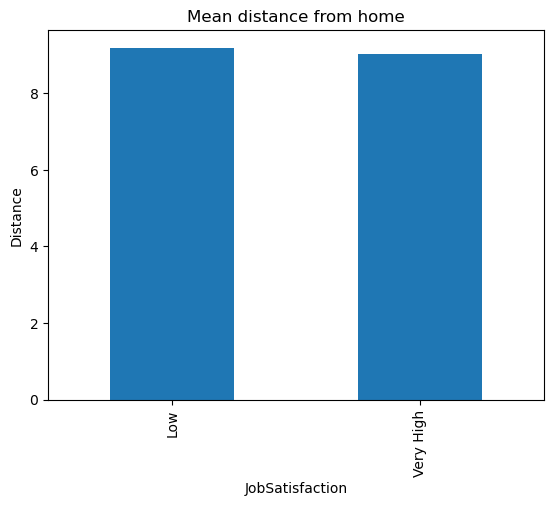

In [44]:
ax = grouped["DistanceFromHome"].mean().plot(kind="bar", title="Mean distance from home")
ax.set_ylabel("Distance");

In [45]:
grouped['HourlyRate'].describe()

,count,mean,std,min,25%,50%,75%,max
JobSatisfaction,,,,,,,,
Low,289.0,68.636678,20.439515,30.0,52.0,72.0,86.0,100.0
Very High,459.0,64.681917,20.647571,30.0,47.0,64.0,82.5,100.0


In [46]:
grouped['MonthlyIncome'].describe()

,count,mean,std,min,25%,50%,75%,max
JobSatisfaction,,,,,,,,
Low,289.0,6561.570934,4645.170134,1091.0,3072.0,4968.0,8564.0,19943.0
Very High,459.0,6472.732026,4573.906428,1051.0,2927.5,5126.0,7908.0,19845.0


In [47]:
grouped['YearsAtCompany'].describe()

,count,mean,std,min,25%,50%,75%,max
JobSatisfaction,,,,,,,,
Low,289.0,6.989619,6.243599,0.0,3.0,5.0,9.0,36.0
Very High,459.0,6.962963,5.900257,0.0,3.0,5.0,10.0,40.0


## Comparing the means of every numeric variable

In [48]:
numeric_cols = subset_of_interest.select_dtypes(include="number").columns

# One row per variable, one column per satisfaction group
mean_comparison_df = grouped[numeric_cols].mean().transpose()
mean_comparison_df

JobSatisfaction,Low,Very High
Age,36.916955,36.795207
DailyRate,782.505190,802.069717
DistanceFromHome,9.190311,9.030501
Education,2.944637,2.901961
EnvironmentSatisfaction,2.743945,2.749455
HourlyRate,68.636678,64.681917
JobLevel,2.055363,2.052288
MonthlyIncome,6561.570934,6472.732026
MonthlyRate,14095.377163,14103.429194
NumCompaniesWorked,2.871972,2.516340


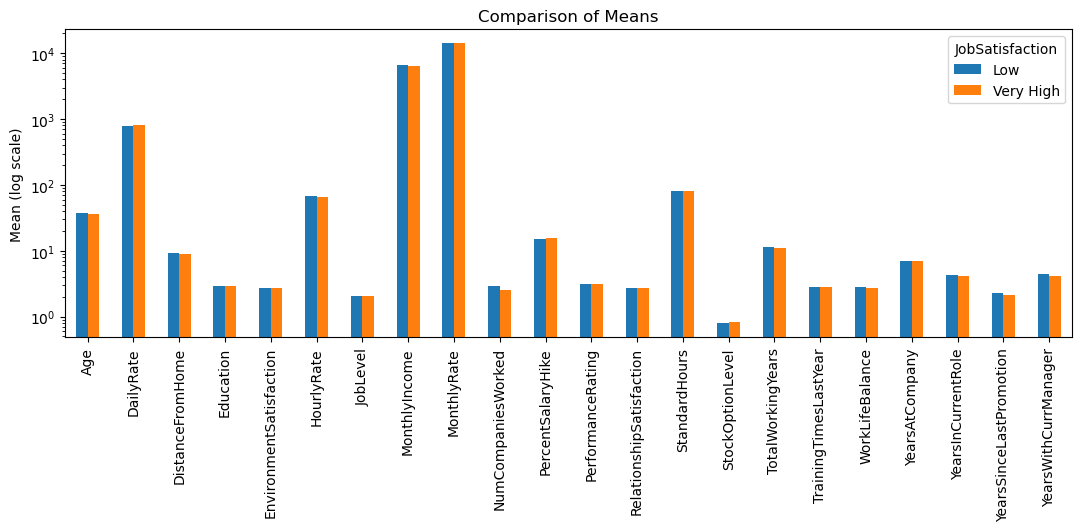

In [49]:
# Variables are on very different scales (e.g. MonthlyIncome vs Age), so a log axis
# keeps the smaller ones visible
ax = mean_comparison_df.plot(kind="bar", figsize=(13, 4), logy=True, title="Comparison of Means")
ax.set_ylabel("Mean (log scale)");